In [6]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from pathlib import Path
from scipy.optimize import least_squares
from scipy.optimize import curve_fit
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

In [7]:
def readfile(fpath):
    with h5py.File(fpath, "r") as f:
        S_complesso = np.array(f["band/S_complex"])
        freq = np.array(f["band/frequency_Hz"])
        volt = np.array(f["band/voltage_V"])
    return S_complesso, freq, volt

In [ ]:
def modello_base(parametri, frequenza_GHz):
    (
        Qr, Qc, phi0, f0,   #parametri risonanza
        a0_re, a0_im,       #parametri fondo complesso
        a1_re, a1_im,
        a2_re, a2_im,
        a3_re, a3_im,
    ) = parametri

    a0 = a0_re + 1j * a0_im
    a1 = a1_re + 1j * a1_im
    a2 = a2_re + 1j * a2_im
    a3 = a3_re + 1j * a3_im

    x = (frequenza_GHz - f0) / f0               #normalizzo la frequenza (scostamento dalla freq di risonanza)
    C = a0 + a1 * x + a2 * x**2 + a3 * x**3     #modello del fondo

    termine_ris = 1 - (                         #modello risonanza
        (Qr / Qc) * np.exp(1j * phi0)
        / (1 + 2j * Qr * x)
    )

    return C * termine_ris

def residui_base(par, freq_GHz, dati):          #concateno le 2 componenti per conservare info complessa
    differenza = modello_base(par, freq_GHz) - dati

    return np.concatenate([
        differenza.real,
        differenza.imag
    ])


def fit_base(S_complesso, freq):
    S_complesso = np.asarray(S_complesso, dtype=complex)
    freq_GHz = np.asarray(freq, dtype=float) / 1e9
    S_modulo = np.abs(S_complesso)

    #STIMA f0
    f0_0 = freq_GHz[np.argmin(S_modulo)]        # stima f0, prendo il minimo di S_modulo

    n_edge = len(freq_GHz) // 10                                # numero di punti che stanno nel 10%
    ind_sx = np.arange(n_edge)                                  # 10% di punti a sx
    ind_dx = np.arange(len(freq_GHz) - n_edge, len(freq_GHz))   # 10% di punti a dx

    #STIMA TAU
    tau_stime = []
    sigma_tau_stima = []

    for indice in (ind_sx, ind_dx):
        fase = np.unwrap(np.angle(S_complesso[indice]))         #calcolo fase nel 10% di punti a sx e dx
        coeff, cov = np.polyfit(freq_GHz[indice], fase, 1, cov=True)     #calcolo pendenza della retta freq_GHz vs fase
        
        pendenza = coeff[0]
        sigma_pendenza = np.sqrt(cov[0, 0])

        tau_stime.append(-pendenza / (2 * np.pi))               #calcolo il ritardo in nanosec
        sigma_tau_stima.append(sigma_pendenza / (2 * np.pi))
    
    tau_ns = np.median(tau_stime)                               #prendo valore mediano di ritardo
    sigma_tau_ns = 0.5 * np.hypot (*sigma_tau_stima)            #combina incertezze delle due stime indipendenti di tau, dai punti a sinistra e da quelli a destra

    #CORREGGO S
    S_corretto = S_complesso * np.exp(                          #correggo eliminando il ritardo stimato
        2j * np.pi * freq_GHz * tau_ns
    )

    #STIMA a0
    ind_bordo = np.concatenate([ind_sx, ind_dx])
    a0 = np.mean(S_corretto[ind_bordo])             #val iniziale di a0 lo prendo come media di S ai bordi

    #PARAMETRI INIZIALI
    parametri_iniziali = [
        5000.0,       # Qr
        10000.0,      # Qc
        0.0,          # phi0
        f0_0,         # f0 [GHz]
        a0.real,      # a0 reale
        a0.imag,      # a0 immaginario
        0.0, 0.0,     # a1 reale e immaginario
        0.0, 0.0,     # a2 reale e immaginario
        0.0, 0.0,     # a3 reale e immaginario
    ]

    #LIMITI AI PARAMETRI
    limiti_inferiori = [
        1.0, 1.0, -np.pi, freq_GHz.min(),
        *([-np.inf] * 8),
        #*([-np.inf] * 4),
    ]
    limiti_superiori = [
        1e7, 1e10, np.pi, freq_GHz.max(),
        *([np.inf] * 8),
        #*([np.inf] * 4),
        
    ]

    dati_fit = np.concatenate((S_corretto.real, S_corretto.imag))
    x_fit = np.arange(dati_fit.size)

    def modello_reale(_, *parametri):
        z = modello_base(parametri, freq_GHz)
        return np.concatenate((z.real, z.imag))

    parametri_fit, covarianza_fit = curve_fit(
        modello_reale,
        x_fit,
        dati_fit,
        p0=parametri_iniziali,
        bounds=(limiti_inferiori, limiti_superiori),
        method="trf",
        max_nfev=10000,
    )

    Qr_fit, Qc_fit, phi0_fit, f0_fit = parametri_fit[:4]
    S_fit = np.abs(modello_base(parametri_fit, freq_GHz))

    varianze = np.diag(covarianza_fit)
    errori_parametri = np.sqrt(np.where(varianze >= 0, varianze, np.nan))    

    #a0_fit = fit.x[4] + 1j * fit.x[5]
    #a1_fit = fit.x[6] + 1j * fit.x[7]
    #a2_fit = fit.x[8] + 1j * fit.x[9]
    #a3_fit = fit.x[10] + 1j * fit.x[11]

    return f0_fit, Qr_fit, Qc_fit, freq, S_modulo, S_fit, tau_ns, sigma_tau_ns, parametri_fit, errori_parametri,

In [9]:
#FIT fr vs I

def modello_g_vs_I(I, I_s2, I_s4):
    return 0.5 * ((I / I_s2)**2 + (I / I_s4)**4)


def fit_g_vs_I(g, I_mA, sigma_g=None):
    I_mA = np.asarray(I_mA, dtype=float)
    g = np.asarray(g, dtype=float)
    sigma_g = np.asarray(sigma_g, dtype=float)

    #ordina i punti in base a I e mantiene le incertezze abbinate ai dati.
    ordine = np.argsort(I_mA)
    I_mA_ordinata = I_mA[ordine]
    g_ordinata = g[ordine]
    sigma_ordinata = sigma_g[ordine]

    # Stima iniziale: A ha dimensioni di GHz^2
    scala_I = np.max(np.abs(I_mA_ordinata))
    p0 = [scala_I, scala_I]

    parametri_fit, covarianza_fit = curve_fit(
        modello_g_vs_I,
        I_mA_ordinata,
        g_ordinata,
        p0=p0,
        bounds=([1e-9, 1e-9], [np.inf, np.inf]),
        sigma=sigma_ordinata,
        absolute_sigma=True,
        maxfev=50000,
    )

    g_fit = modello_g_vs_I(I_mA_ordinata, *parametri_fit)

    return I_mA_ordinata, g_ordinata, g_fit, parametri_fit, covarianza_fit

In [10]:
f_risonanza_list = []
Vbias_list = []
curve_risonanza = []
Qr_list = []
Qc_list = []
ritardo = []
sigma_ritardo = []
sigma_fr_list = []  # incertezze statistiche su fr [GHz]

for i in np.arange(0, 11.30, 0.05):
    fpath = (
        Path(r"C:\Users\loric\Desktop\Unimib\Tesi\Misure")
        / "misure_tutte"
        / "misure_14_10"
        / "autoscan_ok"
        / f"Vbias_{i:.3f}V"
        / f"Run1_V{i:.2f}.h5"
    )
    S_complesso, freq, volt = readfile(fpath)
    
    (
        fr_fit, Qr_fit, Qc_fit, freq, S_mod, S_fit, tau_ns, sigma_tau_ns,
        parametri_fit, errori_parametri, 
    ) = fit_base(S_complesso, freq)
   
    f_risonanza_list.append(fr_fit)
    sigma_fr_list.append(errori_parametri[3])
    Vbias_list.append(i)
    Qr_list.append(Qr_fit)
    Qc_list.append(Qc_fit)
    ritardo.append(tau_ns)
    sigma_ritardo.append(sigma_tau_ns)

    curve_risonanza.append({
    "Vbias": i,
    "freq_GHz": freq / 1e9,
    "S_mod": S_mod,
    "S_fit": S_fit
    })
    
    #print(f"File: {fpath.name}, Frequenza di risonanza: {fr_fit:.8f} GHz, Qr: {Qr_fit:.6g}")




In [11]:

for i in np.arange(11.300, 12.000, 0.054):
    fpath = (
        Path(r"C:\Users\loric\Desktop\Unimib\Tesi\Misure")
        / "misure_tutte"
        / "misure_14_10"
        / "autoscan_ok"
        / f"Vbias_{i:.3f}V"
        / f"Run1_V{i:.2f}.h5"
    )
    S_complesso, freq, volt = readfile(fpath)

    # Seleziona l'intervallo dal margine destro fino a 0.050 GHz più in basso
    freq_max = np.max(freq)
    freq_min_fit = freq_max - 0.080e9  # frequenze in Hz
    maschera_fit = (freq >= freq_min_fit) & (freq <= freq_max)

    freq_selezionata = freq[maschera_fit]
    S_selezionato = S_complesso[maschera_fit]

    (
        fr_fit, Qr_fit, Qc_fit, freq, S_mod, S_fit, tau_ns, sigma_tau_ns,
        parametri_fit, errori_parametri, 
    ) = fit_base(S_selezionato, freq_selezionata)
   
    f_risonanza_list.append(fr_fit)
    sigma_fr_list.append(errori_parametri[3])
    Vbias_list.append(i)
    Qr_list.append(Qr_fit)
    Qc_list.append(Qc_fit)
    ritardo.append(tau_ns)
    sigma_ritardo.append(sigma_tau_ns)
    
    curve_risonanza.append({
        "Vbias": i,
        "freq_GHz": freq / 1e9,
        "S_mod": S_mod,
        "S_fit": S_fit
    })


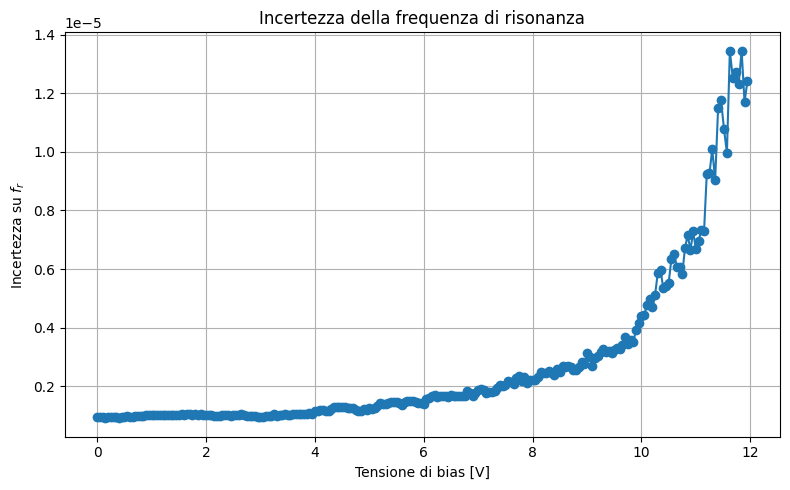

[ 0.93361733  0.93658281  0.93534027  0.9196689   0.93966346  0.95197123
  0.95388015  0.92946723  0.8986187   0.95928837  0.94584351  0.97647891
  0.96136677  0.95034799  0.96697541  0.97181559  0.97370964  0.9848212
  0.99827803  1.00301444  1.01881116  1.00279363  1.01375394  1.01411571
  0.99844552  1.00462574  1.02317314  1.00341262  1.00833463  1.01259889
  1.02151659  1.03010472  1.02033158  1.0352353   1.03058729  1.02507606
  1.0323908   0.99762267  1.03959316  1.02706799  1.00225606  1.00395071
  1.00939168  0.98303288  0.99475105  0.97791476  1.00569445  1.00981177
  1.00713544  0.98627487  1.00650294  1.02457553  1.01560019  1.0346243
  1.00705435  0.97761794  0.96850972  0.97376592  0.98369031  0.95870875
  0.9474956   0.95169096  0.96430757  0.97130166  0.98451881  1.04268691
  0.9943378   1.00378086  1.02113794  1.03060303  1.01776678  1.01398968
  1.05306037  1.04786783  1.04568824  1.05743881  1.05280209  1.03027295
  1.08011517  1.05726962  1.14908459  1.14594463  1.1

In [12]:
Vbias = np.asarray(Vbias_list, dtype=float)
sigma_fr = np.asarray(sigma_fr_list, dtype=float)

ordine = np.argsort(Vbias)

plt.figure(figsize=(8, 5))
plt.plot(Vbias[ordine], sigma_fr[ordine], "o-")
plt.xlabel("Tensione di bias [V]")
plt.ylabel("Incertezza su $f_r$")
plt.title("Incertezza della frequenza di risonanza")
plt.grid(True)
plt.tight_layout()
plt.show()

print(np.asarray(sigma_fr_list) * 1e6, "kHz")

fr = np.asarray(f_risonanza_list, dtype=float)
sigma_fr = np.asarray(sigma_fr_list, dtype=float)
errore_relativo_percento = sigma_fr / np.abs(fr) * 100

for bias, err in zip(Vbias_list, errore_relativo_percento):
    print(f"Vbias = {bias:.3f} V: errore relativo su fr = {err:.4g}%")

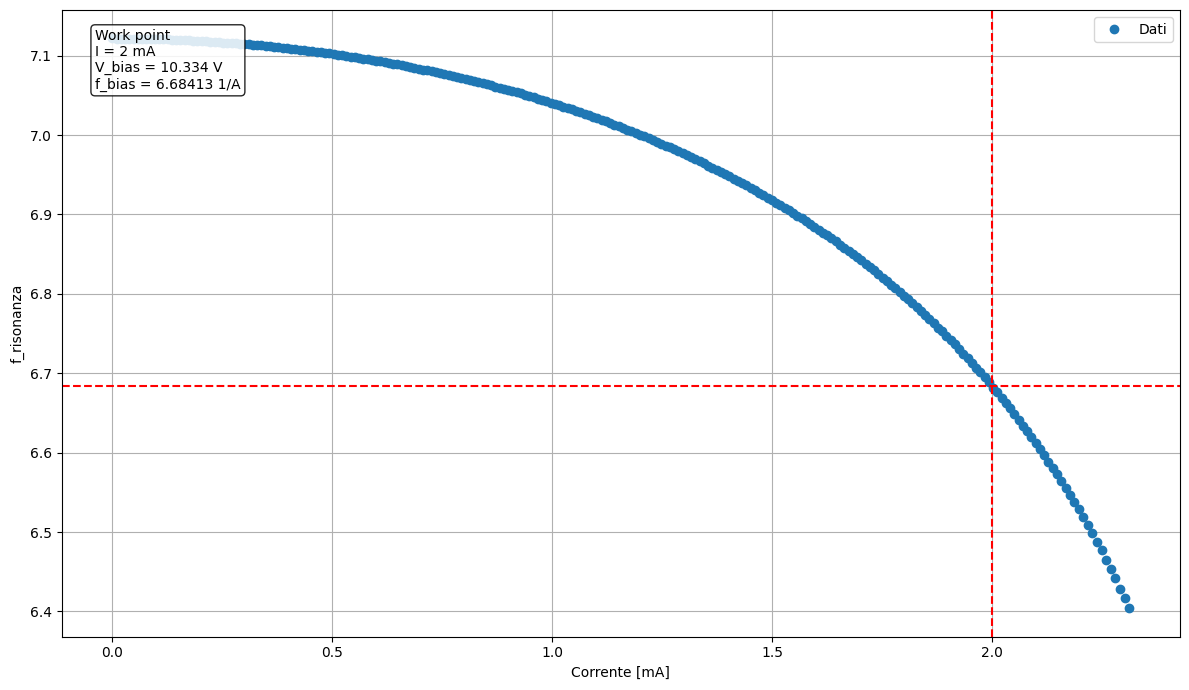

In [13]:
R = 5167.0
I_mA = np.asarray(Vbias_list, dtype=float) / R * 1e3
I_A = np.asarray(I_mA, dtype=float) * 1e-3
f_ris = np.asarray(f_risonanza_list, dtype=float)

fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(I_mA, f_risonanza_list, "o", label="Dati")
ax.set_ylabel("f_risonanza")
ax.set_xlabel("Corrente [mA]")

I_target_mA = 2.0
V_bias = (I_target_mA * 1e-3) * R  # 2 mA convertiti in A, poi legge di Ohm

# Interpola il valore della curva in corrispondenza di 2 mA
ordine = np.argsort(I_mA)
f_bias = np.interp(I_target_mA, np.asarray(I_mA)[ordine], f_ris[ordine])

ax.axvline(I_target_mA, color="red", linestyle="--")
ax.axhline(f_bias, color="red", linestyle="--")

ax.text(
    0.03, 0.97,
    f"Work point\n"
    f"I = {I_target_mA:g} mA\n"
    f"V_bias = {V_bias:.3f} V\n"
    f"f_bias = {f_bias:g} 1/A",
    transform=ax.transAxes,
    va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85}
)

ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()


Parametri: [6.93342776 4.29063704]


C:\Users\loric\AppData\Local\Temp\ipykernel_2956\2419629619.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


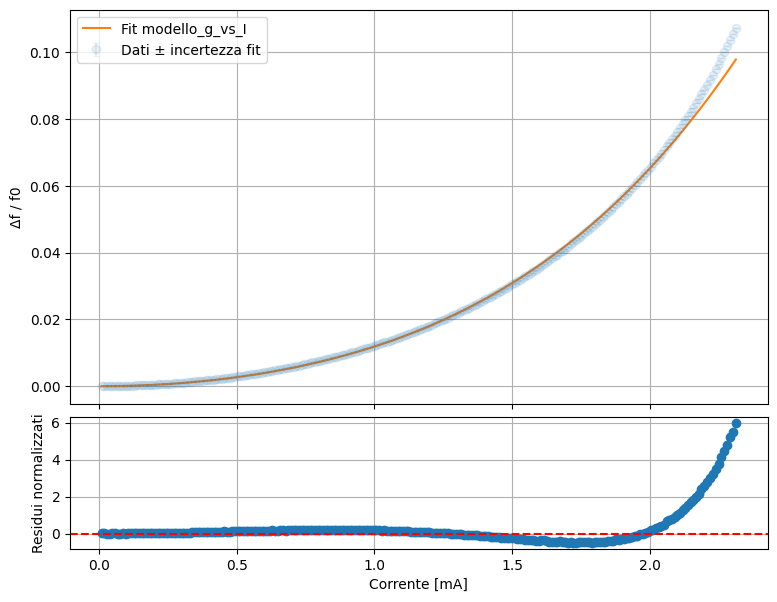

In [14]:
fr = np.asarray(f_risonanza_list, dtype=float)
sigma_fr = np.asarray(sigma_fr_list, dtype=float)  # stessa unità di fr

f_ref = f_bias
sigma_ref = sigma_fr[0]

g = np.abs((fr - fr[0]) / f_ref)
sigma_g_list = np.sqrt((sigma_fr / f_ref)**2 + (fr * sigma_ref / f_ref**2)**2)

# Il primo dato è usato anche come riferimento: g[0] è zero per definizione.
sigma_g_list[0] = 0.0

maschera = np.arange(fr.size) != 0

I_fit, g_dati, g_fit, parametri_fit, covarianza_fit = fit_g_vs_I(g[maschera], I_mA[maschera], sigma_g_list[maschera])

# Riordino le incertezze nello stesso ordine di corrente usato da fit_g_vs_I.
sigma_g_dati = sigma_g_list[maschera][np.argsort(I_mA[maschera])]
residui_normalizzati = (g_dati - g_fit) / np.std(g_dati - g_fit)

print("Parametri:", parametri_fit)

# Grafici del fit e dei residui
fig, (ax_fit, ax_residui) = plt.subplots(
    2, 1,
    figsize=(9, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05}
)

ax_fit.errorbar(
    I_fit, g_dati, yerr=sigma_g_dati,
    fmt="o", capsize=2, alpha=0.1, label="Dati ± incertezza fit"
)
#ax_fit.plot(I_fit, fr_dati, "o", label="Dati")
ax_fit.plot(I_fit, g_fit, "-", label="Fit modello_g_vs_I")
ax_fit.set_ylabel("Δf / f0")
ax_fit.legend()
ax_fit.grid(True)

ax_residui.plot(I_fit, residui_normalizzati, "o")
ax_residui.axhline(0, color="red", linestyle="--")
ax_residui.set_xlabel("Corrente [mA]")
ax_residui.set_ylabel("Residui normalizzati")
ax_residui.grid(True)
plt.tight_layout()
plt.show()


responsivity a I = 1.43 mA è 44.97104677557083
responsivity a I = 2.00 mA è 99.70360525101495
responsivity a I = 2.17 mA è 135.73321168667985


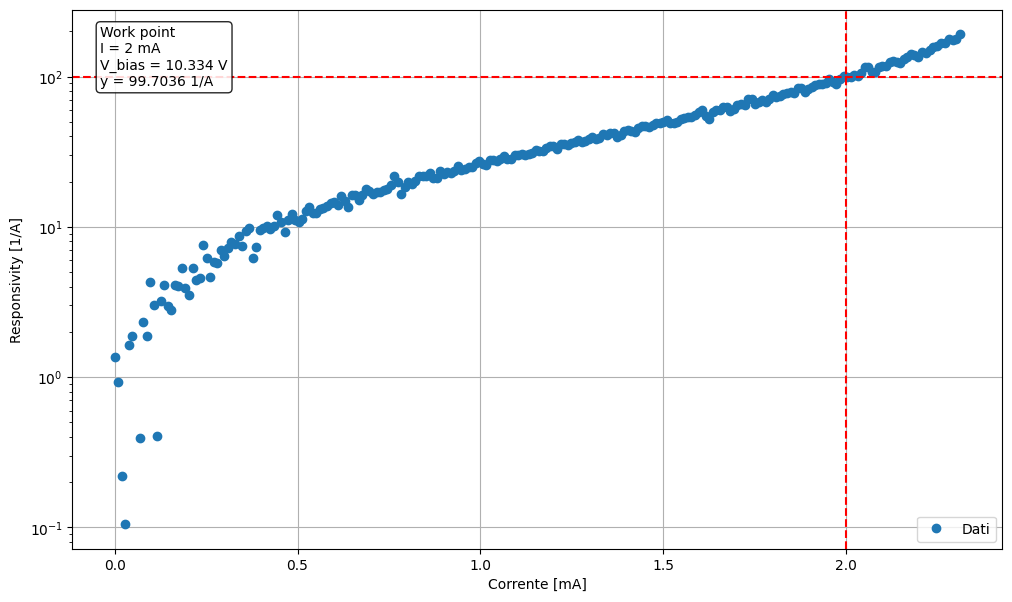

In [15]:
I_A = np.asarray(I_mA, dtype=float) * 1e-3
responsivity = np.gradient(g, I_A)

fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(I_mA, responsivity, "o", label="Dati")
ax.set_ylabel("Responsivity [1/A]")
ax.set_xlabel("Corrente [mA]")
ax.set_yscale("log")
ax.legend()
ax.grid(True)

I_target_mA = 2.0
V_bias = (I_target_mA * 1e-3) * R  # 2 mA convertiti in A, poi legge di Ohm

# Interpola il valore della curva in corrispondenza di 2 mA
ordine = np.argsort(I_mA)
y_target = np.interp(I_target_mA, np.asarray(I_mA)[ordine], responsivity[ordine])

r_2_00 = y_target
r_1_47 = np.interp(1.43, np.asarray(I_mA)[ordine], responsivity[ordine])
r_2_17 = np.interp(2.17, np.asarray(I_mA)[ordine], responsivity[ordine])

ax.axvline(I_target_mA, color="red", linestyle="--")
ax.axhline(y_target, color="red", linestyle="--")

ax.text(
    0.03, 0.97,
    f"Work point\n"
    f"I = {I_target_mA:g} mA\n"
    f"V_bias = {V_bias:.3f} V\n"
    f"y = {y_target:g} 1/A",
    transform=ax.transAxes,
    va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85}
)
ax.legend()
plt.tight_layout
plt.show

print ("responsivity a I = 1.43 mA è", r_1_47)
print ("responsivity a I = 2.00 mA è", r_2_00)
print ("responsivity a I = 2.17 mA è", r_2_17)


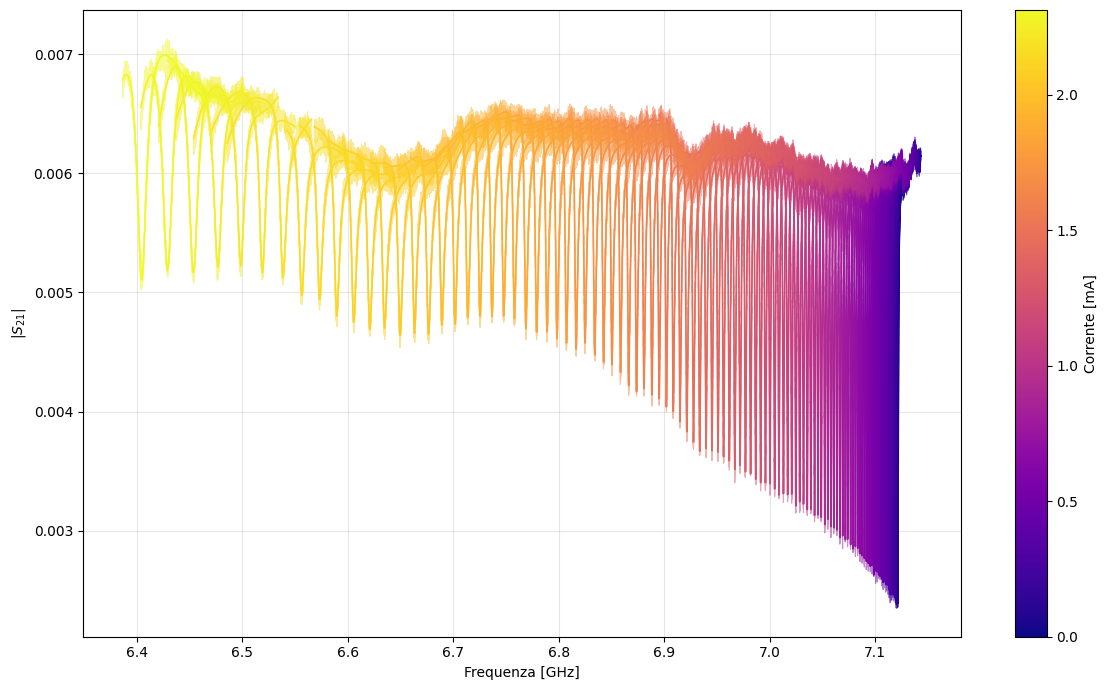

In [16]:
fig, ax = plt.subplots(figsize=(12, 7))

#curve_risonanza contiene un dizionario per ogni curva di risonanza, "Vbias", "freq_GHz", "S_mod", "S_fit"

# trovo i valori minimi e massimi di Vbias
v_min = min(c["Vbias"] for c in curve_risonanza)
v_max = max(c["Vbias"] for c in curve_risonanza)

R_ohm = 5167.0

correnti_mA = [
    c["Vbias"] / R_ohm * 1e3
    for c in curve_risonanza
]

norm = Normalize(vmin=min(correnti_mA), vmax=max(correnti_mA)) #normalizzazione dei valori di Vbias per la mappatura dei colori
cmap = plt.get_cmap("plasma") #viridis o plasma sono le palette di colori
#plasma, viridis, inferno, magma, cividis, twilight, turbo, gist_earth, ocean, terrain, gist_stern, gist_rainbow


# Seleziona una curva ogni N misure
passo = 2
curve_selezionate = curve_risonanza[::passo]

for c in curve_selezionate:
    corrente_mA = c["Vbias"] / R_ohm * 1e3
    colore = cmap(norm(corrente_mA)) #assegno il colore per ogni curva in base al valore di corrente

    ax.plot(
        c["freq_GHz"], c["S_mod"],
        color=colore, alpha=0.5, linewidth=0.8 #alpha = trasparenza dei dati sperimentali
    )
    ax.plot(
        c["freq_GHz"], c["S_fit"],
        color=colore, linewidth=1.2
    )

ax.set_xlabel("Frequenza [GHz]")
ax.set_ylabel(r"$|S_{21}|$")

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Corrente [mA]")

ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


Ritardo medio: 66.1170572649596 ns
Metri di cavi: 13.091177338462 m


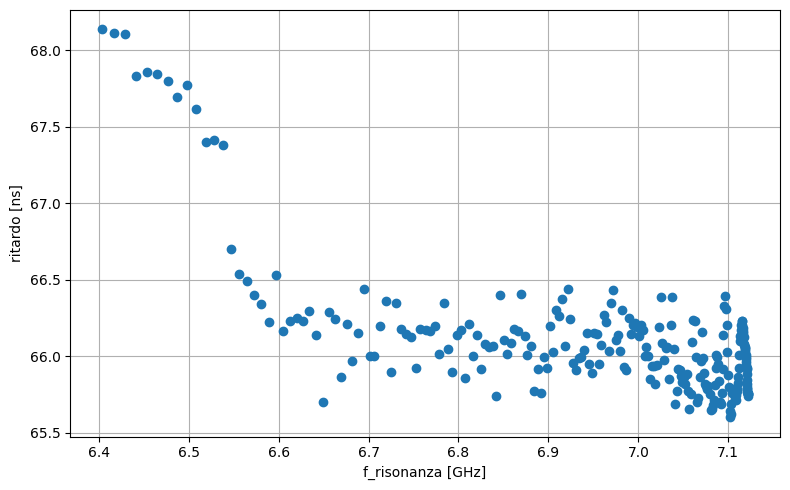

In [17]:
print (f"Ritardo medio: {np.mean(ritardo)} ns")

L = 0.66*3e8*np.mean(ritardo)*1e-9

print (f"Metri di cavi: {L} m")

ritardo_array = np.asarray(ritardo, dtype=float)

#ordine = np.argsort(f_risonanza_list)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(f_risonanza_list, ritardo_array, "o")
ax.set_xlabel("f_risonanza [GHz]")
ax.set_ylabel("ritardo [ns]")
ax.grid(True)
plt.tight_layout()
plt.show()



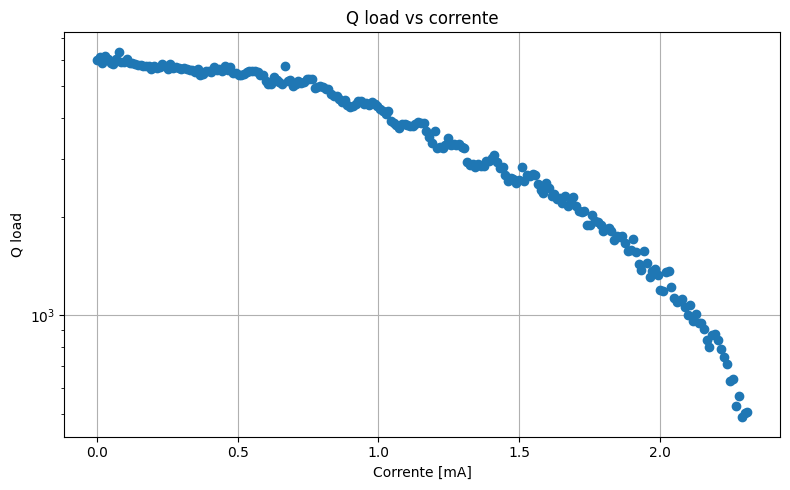

In [18]:
Qload_array = np.asarray(Qr_list, dtype=float)

ordine = np.argsort(I_mA)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(I_mA[ordine], Qload_array[ordine], "o")
ax.set_yscale("log")
ax.set_xlabel("Corrente [mA]")
ax.set_ylabel("Q load")
ax.set_title("Q load vs corrente")
ax.set_ylim(Qload_array.min() / 1.15, Qload_array.max() * 1.15)
ax.grid(True)
plt.tight_layout()
plt.show()